# Specification stability of the production spec

The production model is one specification chosen once. This asks how much of what it says survives
the other choices that could have been made: for **each variable in the spec in turn**, treat it as
the focal regressor and refit across every combination of the remaining six as controls —
2⁶ = 64 specifications per focal variable — using
[`robustipy`](https://pypi.org/project/robustipy/).

What that answers, per variable:

- does its coefficient **keep its sign** across all 64 specifications?
- how wide is the spread between the most and least favourable specification?
- is the production specification typical, or is it at an edge of the distribution?

A variable whose sign flips depending on which controls are included is not delivering a stable
message, whatever its p-value in the one specification we report.

In [1]:
import itertools
import re
import sys
from pathlib import Path

# put src/ on the path — this notebook lives in src/analysis_notebooks/
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'params.py').exists())
sys.path.insert(0, str(SRC))

import warnings
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from robustipy.models import OLSRobust

import model_performance as mp   # loco() and pooled_r2() — the same code 02 reports from
import params
import plotting as plot
plot.STYLE=dict(plot.STYLE); plot.STYLE["save"]=True

warnings.filterwarnings('ignore')

NOTEBOOK = '14_specification_stability'
CFG = params.FINAL_MODEL
SPEC = CFG['spec']

# 64 control combinations per focal variable; draws is the bootstrap within each.
DRAWS, KFOLD = 100, 5
OOS_METRIC, N_CPU = 'pseudo-r2', 4
OUTCOMES = CFG['outcome_vars']          # ['ggi', 'wom', 'men']

print('spec      :', ' + '.join(SPEC))
print('focal vars:', len(SPEC), '| specifications each:', 2 ** (len(SPEC) - 1))

spec      : fb_18_999_men + fb_18_999_wom + fb_18_999_r + hdi + gdi + gdp_pcap + year
focal vars: 7 | specifications each: 64


## 1. The estimation sample

The production panel, unchanged — `keep_itu=True`, complete cases on the spec (D37).

In [2]:
def load(indicator):
    data = pd.read_csv(params.PROCESSED / 'combined_data/updated_ground_truth_and_fb'
                       / indicator / CFG['dataset'])
    data['year'] = data[f'{indicator}_year'] - CFG['year_origin']
    return data


panels = {i: load(i) for i in CFG['indicators']}
for indicator, data in panels.items():
    complete = data.dropna(subset=SPEC + [f'{indicator}_{o}' for o in OUTCOMES])
    print(f'{indicator:9s} {len(data):4d} rows -> {len(complete):4d} complete')

internet   108 rows ->  108 complete
mobile      99 rows ->   99 complete


## 2. Loop every spec variable as the focal X

Each fit holds one variable as the estimand and sweeps the power set of the other six.

In [3]:
def stability(data, outcome, focal, controls):
    """robustipy over every subset of `controls`, with `focal` as the estimand"""
    frame = data.dropna(subset=SPEC + [outcome])
    model = OLSRobust(y=[outcome], x=[focal], data=frame)
    # every argument is passed explicitly: robustipy prompts interactively for any it is not
    # given, which hangs a non-interactive run
    model.fit(controls=controls, draws=DRAWS, kfold=KFOLD, oos_metric=OOS_METRIC,
              seed=params.SEED, n_cpu=N_CPU, compute_shap=False)
    return model.get_results().summary_df


records, curves = [], []

for indicator, data in panels.items():
    for outcome_var in OUTCOMES:
        outcome = f'{indicator}_{outcome_var}'
        # the coefficient the production model actually reports, for reference
        full = sm.OLS(data[outcome], sm.add_constant(data[SPEC]), missing='drop').fit()

        for focal in SPEC:
            summary = stability(data, outcome, focal, [c for c in SPEC if c != focal])
            median = summary['median']

            records.append({
                'indicator': indicator, 'outcome': outcome_var, 'focal': focal,
                'n_specs': len(summary),
                'production_coef': float(full.params[focal]),
                'production_p': float(full.pvalues[focal]),
                'median_coef': float(median.median()),
                'min_coef': float(summary['min'].min()),
                'max_coef': float(summary['max'].max()),
                'share_positive': float((median > 0).mean()),
                'sign_stable': bool((median > 0).all() or (median < 0).all()),
                'share_ci_excludes_0': float(((summary['ci_down'] > 0)
                                              | (summary['ci_up'] < 0)).mean()),
                'median_r2': float(summary['r2'].median()),
                'median_oos': float(summary['av_k_metric'].median()),
            })
            curves.append(summary.assign(indicator=indicator, outcome=outcome_var, focal=focal))
            print(f'  {indicator:9s} {outcome_var:4s} {focal:16s} '
                  f'median {median.median():+.4f}  sign stable: {records[-1]["sign_stable"]}')

stability_summary = pd.DataFrame(records)
curve_data = pd.concat(curves, ignore_index=True)
print(f'\n{len(stability_summary)} focal-variable runs, {len(curve_data)} specifications total')

OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is fb_18_999_men. Let's begin the calculations...
Total model runs: 6,400 (draws=100, control_specs=64, y_composites=1)


Bootstrap draws:   0.0%|          | 0/6400 [00:00<?, ?draw/s]

  internet  ggi  fb_18_999_men    median +0.2893  sign stable: False
OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is fb_18_999_wom. Let's begin the calculations...
Total model runs: 6,400 (draws=100, control_specs=64, y_composites=1)


Bootstrap draws:   0.0%|          | 0/6400 [00:00<?, ?draw/s]

  internet  ggi  fb_18_999_wom    median +0.2109  sign stable: False
OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is fb_18_999_r. Let's begin the calculations...
Total model runs: 6,400 (draws=100, control_specs=64, y_composites=1)


...

  mobile    men  gdi              median -0.5167  sign stable: False
OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is gdp_pcap. Let's begin the calculations...
Total model runs: 6,400 (draws=100, control_specs=64, y_composites=1)


Bootstrap draws:   0.0%|          | 0/6400 [00:00<?, ?draw/s]

  mobile    men  gdp_pcap         median +0.0765  sign stable: True
OLSRobust is running with n_cpu=4, draws=100, folds=5, seed=42.
We're evaluating our out-of-sample predictions with the pseudo-r2 metric.
The estimand of interest is year. Let's begin the calculations...
Total model runs: 6,400 (draws=100, control_specs=64, y_composites=1)


Bootstrap draws:   0.0%|          | 0/6400 [00:00<?, ?draw/s]

  mobile    men  year             median +0.0088  sign stable: True

42 focal-variable runs, 2688 specifications total


## 3. Which variables are stable?

`sign_stable` is the headline: across all 64 control combinations, does the coefficient ever cross
zero. `share_ci_excludes_0` is the softer version — the fraction of specifications in which the
bootstrap interval clears zero.

In [4]:
stability_summary[['indicator', 'outcome', 'focal', 'production_coef', 'median_coef',
                   'min_coef', 'max_coef', 'sign_stable', 'share_positive',
                   'share_ci_excludes_0']].round(4)

,indicator,outcome,focal,production_coef,median_coef,min_coef,max_coef,sign_stable,share_positive,share_ci_excludes_0
0,internet,ggi,fb_18_999_men,0.7752,0.2893,-0.6120,1.3281,False,0.9688,0.8594
1,internet,ggi,fb_18_999_wom,-0.7305,0.2109,-1.3457,1.1727,False,0.6562,0.7812
2,internet,ggi,fb_18_999_r,0.5062,0.4512,-0.2492,1.2116,True,1.0000,0.9062
3,internet,ggi,hdi,0.2592,0.5412,-0.6296,2.1738,True,1.0000,0.7031
4,internet,ggi,gdi,1.3733,1.6645,0.1190,4.1552,True,1.0000,1.0000
5,internet,ggi,gdp_pcap,0.0049,0.0152,-0.1277,0.1432,False,0.6094,0.3906
6,internet,ggi,year,0.0092,0.0128,-0.0123,0.0799,True,1.0000,0.3594
7,internet,wom,fb_18_999_men,0.5261,0.3518,-0.7420,1.2348,False,0.9688,0.9062
8,internet,wom,fb_18_999_wom,-0.3511,0.2836,-1.0304,1.6120,False,0.6719,0.5625
9,internet,wom,fb_18_999_r,0.1226,0.1697,-0.5666,1.1495,False,0.8906,0.3438


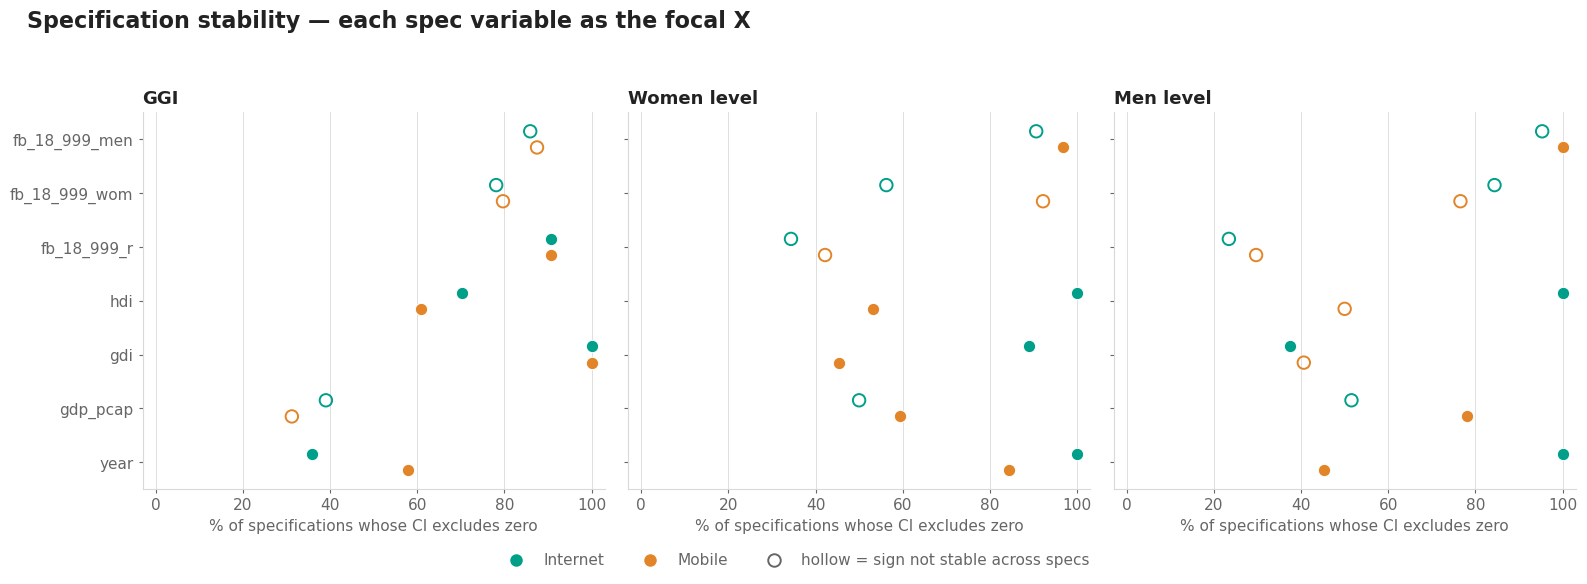

In [5]:
fig, axes = plt.subplots(1, len(OUTCOMES), figsize=(16, 5.5), sharey=True)

for ax, outcome_var in zip(np.atleast_1d(axes), OUTCOMES):
    block = stability_summary[stability_summary['outcome'] == outcome_var]
    y = np.arange(len(SPEC))
    for k, indicator in enumerate(CFG['indicators']):
        sub = block[block['indicator'] == indicator].set_index('focal').reindex(SPEC)
        offset = (k - 0.5) * 0.3
        # a hollow marker where the sign is not stable: the value is there, the claim is not
        for i, (_, r) in enumerate(sub.iterrows()):
            filled = bool(r['sign_stable'])
            ax.scatter(r['share_ci_excludes_0'] * 100, y[i] + offset, s=80,
                       facecolor=plot.PALETTE[k] if filled else 'none',
                       edgecolor=plot.PALETTE[k] if not filled else 'white',
                       linewidth=1.4 if not filled else 0.8, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(SPEC)
    ax.set_ylim(len(SPEC) - 0.5, -0.5)
    ax.set_xlim(-3, 103)
    plot.tidy(ax, title={'ggi': 'GGI', 'wom': 'Women level', 'men': 'Men level'}[outcome_var],
              xlabel='% of specifications whose CI excludes zero', grid='x')

handles = [plot.swatch(plot.PALETTE[k], i.capitalize(), marker='o')
           for k, i in enumerate(CFG['indicators'])]
handles.append(plt.Line2D([], [], marker='o', linestyle='None', markersize=9,
                          markerfacecolor='none', markeredgecolor=plot.MUTED,
                          markeredgewidth=1.4, label='hollow = sign not stable across specs'))
plot.legend(fig, handles, y=-0.06)
plot.suptitle(fig, 'Specification stability — each spec variable as the focal X')
fig.tight_layout(rect=(0, 0, 1, 0.93))
plot.save(fig, NOTEBOOK, 'specification_stability')
plt.show()

## 4. The specification curves

One panel per focal variable: the median coefficient in each of the 64 specifications, sorted. A
flat curve is a variable whose message does not depend on the control set; a curve crossing zero is
one whose message does. The production specification is marked.

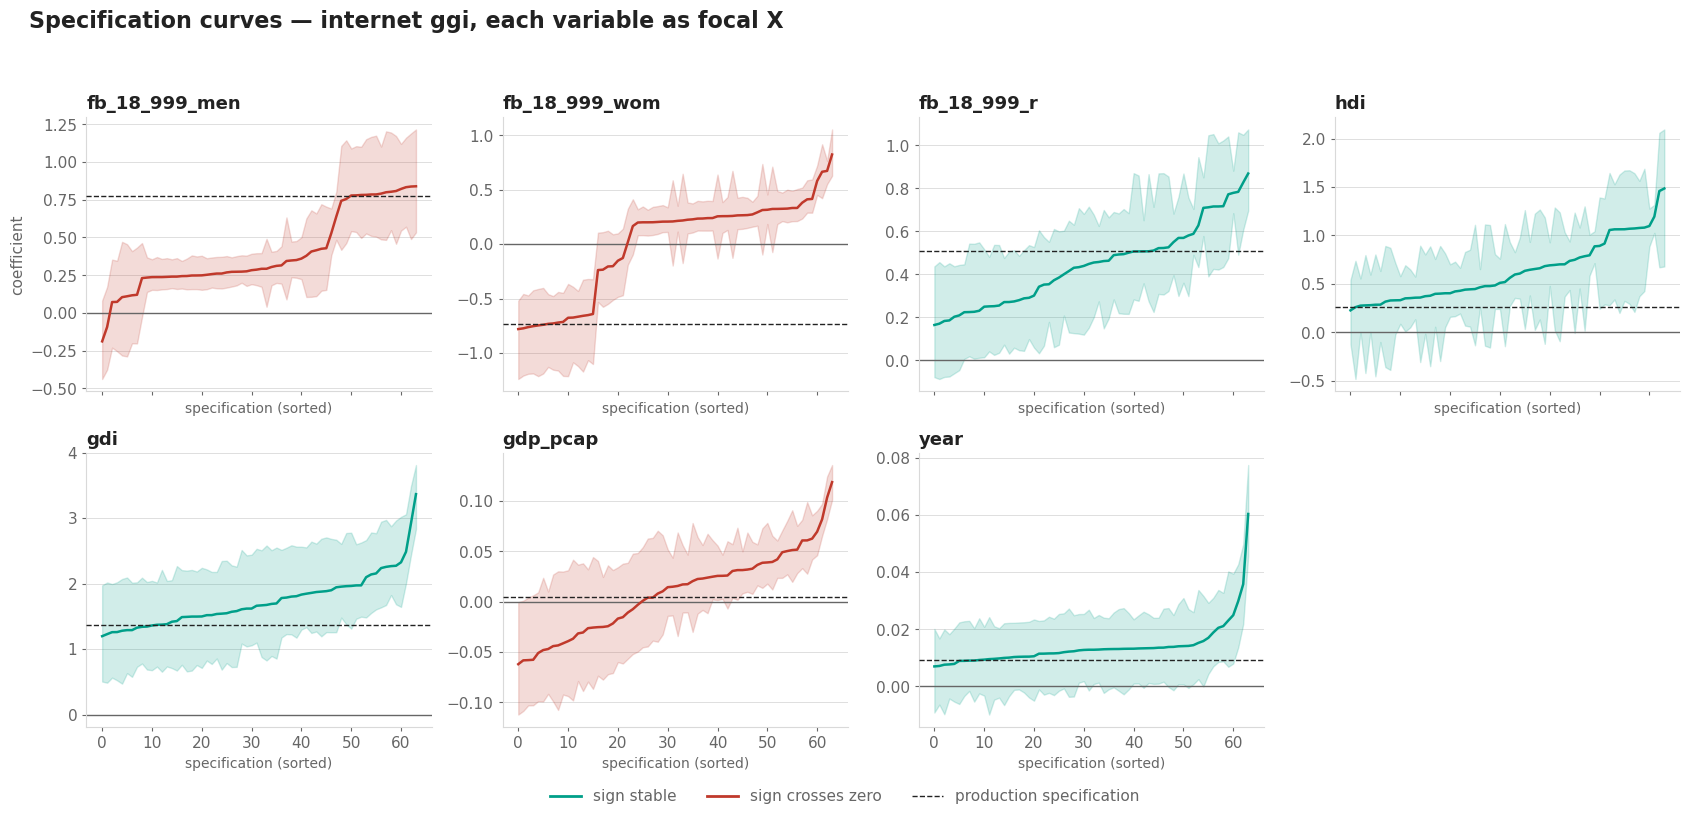

In [6]:
INDICATOR, OUTCOME_VAR = 'internet', 'ggi'   # change to redraw for another target

block = curve_data[(curve_data['indicator'] == INDICATOR)
                   & (curve_data['outcome'] == OUTCOME_VAR)]
prod = stability_summary[(stability_summary['indicator'] == INDICATOR)
                         & (stability_summary['outcome'] == OUTCOME_VAR)].set_index('focal')

fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharex=True)
for ax, focal in zip(axes.ravel(), SPEC):
    sub = block[block['focal'] == focal].sort_values('median').reset_index(drop=True)
    x = np.arange(len(sub))
    crosses = (sub['median'] > 0).any() and (sub['median'] < 0).any()
    colour = plot.PALETTE[0] if not crosses else plot.FLAG

    ax.fill_between(x, sub['ci_down'], sub['ci_up'], color=colour, alpha=0.18, zorder=1)
    ax.plot(x, sub['median'], color=colour, linewidth=1.8, zorder=3)
    ax.axhline(0, color=plot.MUTED, linewidth=1, zorder=2)
    ax.axhline(prod.loc[focal, 'production_coef'], color=plot.INK, linewidth=1,
               linestyle='--', zorder=4)
    plot.tidy(ax, title=focal, grid='y')
    ax.set_xlabel('specification (sorted)', fontsize=plot.STYLE['tick_fs'] - 1, color=plot.MUTED)

for ax in axes.ravel()[len(SPEC):]:
    ax.set_visible(False)

axes[0, 0].set_ylabel('coefficient', fontsize=plot.STYLE['tick_fs'], color=plot.MUTED)
plot.legend(fig, [plt.Line2D([], [], color=plot.PALETTE[0], linewidth=2, label='sign stable'),
                  plt.Line2D([], [], color=plot.FLAG, linewidth=2, label='sign crosses zero'),
                  plt.Line2D([], [], color=plot.INK, linewidth=1, linestyle='--',
                             label='production specification')], y=-0.03)
plot.suptitle(fig, f'Specification curves — {INDICATOR} {OUTCOME_VAR}, each variable as focal X')
fig.tight_layout(rect=(0, 0.01, 1, 0.94))
plot.save(fig, NOTEBOOK, f'specification_curves_{INDICATOR}_{OUTCOME_VAR}')
plt.show()

## 5. Does the fit move as much as the coefficients?

The 42 focal-variable runs above cover 2,688 fits but only **127 distinct specifications** — every
non-empty subset of the seven spec variables. A subset of size *k* is fitted *k* times, once for
each of its members' turn as the focal X, so deduplicating on the full regressor set leaves one row
per specification.

Sections 3 and 4 ask whether a *coefficient* survives the control set. This asks whether the
**fit** does: could one of the other 126 specifications have given a materially better model than
the one we publish?

Every specification is rescored here rather than read off the sweep, and scored the project's own
way — `model_performance.loco`, leave-one-country-out, so the numbers are directly comparable to
`02_model_performance.ipynb`. `robustipy`'s columns are carried alongside for reference: its `r2`
is a statistic over the bootstrap draws rather than the OLS point estimate, which is why it sits
below `r2` and is not exactly monotone in nesting.

In [7]:
def spec_fit_table():
    """in-sample R2, LOCO R2 and LOCO MAE for every non-empty subset of the spec"""
    rows = []
    for indicator, data in panels.items():
        for outcome_var in OUTCOMES:
            outcome = f'{indicator}_{outcome_var}'
            for size in range(1, len(SPEC) + 1):
                for subset in itertools.combinations(SPEC, size):
                    spec = list(subset)
                    fit = sm.OLS(data[outcome], sm.add_constant(data[spec]), missing='drop').fit()
                    y, pred = mp.loco(data, spec, outcome, CFG['leave_column'])
                    rows.append({
                        'indicator': indicator, 'outcome': outcome_var, 'k': size,
                        # SPEC order, so the label of a subset is the same string everywhere
                        'spec': ' + '.join(v for v in SPEC if v in subset),
                        'n': int(fit.nobs), 'n_countries': int(data[CFG['leave_column']].nunique()),
                        'r2': float(fit.rsquared), 'loco_r2': mp.pooled_r2(y, pred),
                        'loco_mae': float((y - pred).abs().mean()),
                    })
    return pd.DataFrame(rows)


spec_fit = spec_fit_table()
spec_fit['is_production'] = spec_fit['k'] == len(SPEC)

def full_regressors(spec_name, focal):
    """
    the full regressor set of a robustipy row: its controls plus the run's focal X

    `spec_name` is a frozenset in memory and its repr once the table has been through a CSV, so
    both are accepted — the section is meant to be re-runnable against a saved sweep.
    """
    controls = (spec_name if isinstance(spec_name, (set, frozenset))
                else re.findall(r"'([^']+)'", str(spec_name)))
    return ' + '.join(v for v in SPEC if v in (set(controls) | {focal}))


# robustipy's own numbers for the same specifications, keyed on that full set
robust = curve_data.assign(spec=[full_regressors(name, focal) for name, focal
                                 in zip(curve_data['spec_name'], curve_data['focal'])])
dup_spread = (robust.groupby(['indicator', 'outcome', 'spec'])['r2']
              .apply(lambda s: s.max() - s.min()).max())
robust = (robust.drop_duplicates(['indicator', 'outcome', 'spec'])
          [['indicator', 'outcome', 'spec', 'r2', 'av_k_metric']]
          .rename(columns={'r2': 'robustipy_r2', 'av_k_metric': 'robustipy_oos'}))
spec_fit = spec_fit.merge(robust, on=['indicator', 'outcome', 'spec'], how='left')
assert spec_fit['robustipy_r2'].notna().all(), 'a specification did not match the sweep'

# every subset keeps the whole sample, so R2 is comparable across the 127 — worth asserting
# rather than assuming, since a spec variable with missing rows would silently change the sample
assert spec_fit.groupby('indicator')['n'].nunique().eq(1).all(), 'the sample moves between specs'

print(f'{len(spec_fit)} rows | {spec_fit.groupby(["indicator", "outcome"]).size().unique()} '
      f'specifications per target')
print(f'sample: ' + ', '.join(f'{i} n={g["n"].iloc[0]} over {g["n_countries"].iloc[0]} countries'
                              for i, g in spec_fit.groupby('indicator')))
print(f'max r2 spread within a duplicated robustipy specification: {dup_spread:.1e}')
print(f'robustipy_r2 sits {(spec_fit["r2"] - spec_fit["robustipy_r2"]).mean():+.3f} from the OLS '
      'R2 on average — a bootstrap statistic, not the point estimate\n')
print(spec_fit.groupby(['indicator', 'outcome'])[['r2', 'loco_r2', 'loco_mae']]
      .agg(['min', 'median', 'max']).round(3).to_string())

762 rows | [127] specifications per target
sample: internet n=108 over 95 countries, mobile n=99 over 83 countries
max r2 spread within a duplicated robustipy specification: 6.7e-16
robustipy_r2 sits +0.011 from the OLS R2 on average — a bootstrap statistic, not the point estimate

                      r2               loco_r2               loco_mae              
                     min median    max     min median    max      min median    max
indicator outcome                                                                  
internet  ggi      0.281  0.751  0.828   0.254  0.724  0.797    0.081  0.100  0.170
          men      0.383  0.817  0.873   0.359  0.795  0.847    0.082  0.099  0.183
          wom      0.388  0.865  0.905   0.364  0.850  0.888    0.084  0.098  0.218
mobile    ggi      0.081  0.667  0.739   0.046  0.625  0.691    0.063  0.073  0.122
          men      0.073  0.468  0.634   0.031  0.398  0.577    0.075  0.093  0.119
          wom      0.101  0.687  0.796   0.06

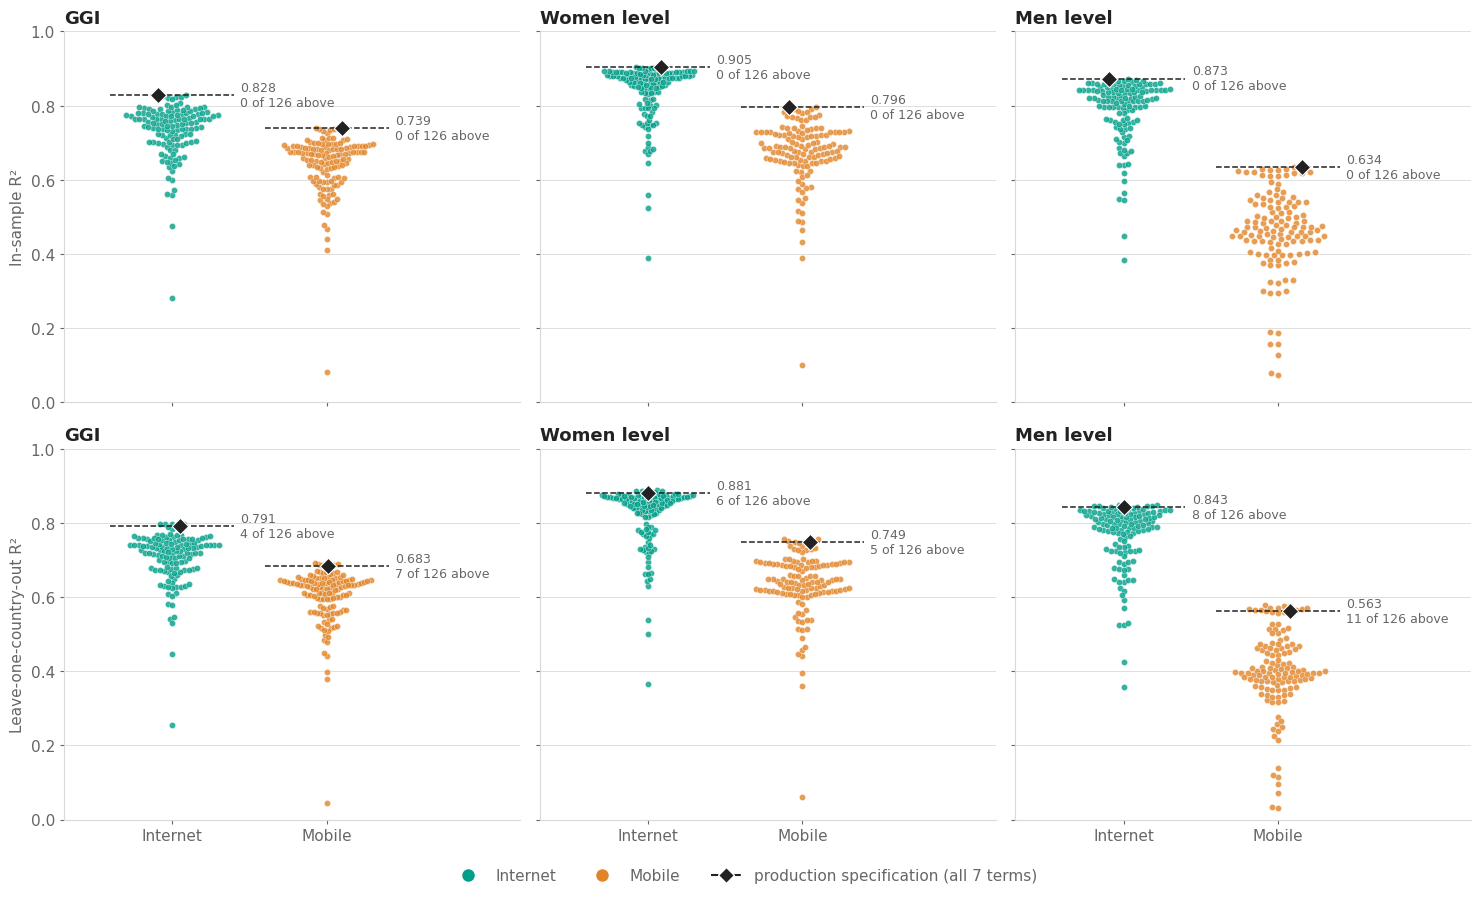

In [8]:
METRICS = [('r2', 'In-sample R²'), ('loco_r2', 'Leave-one-country-out R²')]
LABELS = {'ggi': 'GGI', 'wom': 'Women level', 'men': 'Men level'}

fig, axes = plt.subplots(len(METRICS), len(OUTCOMES), figsize=(15, 9.5), sharex=True, sharey=True)
for row, (metric, metric_label) in enumerate(METRICS):
    for col, outcome_var in enumerate(OUTCOMES):
        ax = axes[row, col]
        for k, indicator in enumerate(CFG['indicators']):
            block = spec_fit[(spec_fit['indicator'] == indicator)
                             & (spec_fit['outcome'] == outcome_var)]
            xs = plot.beeswarm(ax, block[metric].to_numpy(), centre=k, width=0.30,
                               colour=plot.PALETTE[k], size=20, alpha=0.8)
            # the production specification, marked in ink: the reference every dot is read against
            at = block['is_production'].to_numpy()
            value = block[metric].to_numpy()[at][0]
            ax.hlines(value, k - 0.40, k + 0.40, color=plot.INK, linewidth=1.1,
                      linestyle='--', zorder=5)
            ax.scatter(xs[at], value, s=70, marker='D', facecolor=plot.INK,
                       edgecolor='white', linewidth=0.8, zorder=6)
            ax.annotate(f'{value:.3f}\n{int((block[metric] > value).sum())} of '
                        f'{len(block) - 1} above', (k + 0.44, value), ha='left', va='center',
                        fontsize=plot.STYLE['tick_fs'] - 2, color=plot.MUTED)
        ax.set_xlim(-0.7, 2.25)
        ax.set_ylim(0, 1)
        ax.set_xticks(range(len(CFG['indicators'])))
        ax.set_xticklabels([i.capitalize() for i in CFG['indicators']])
        plot.tidy(ax, title=LABELS[outcome_var], grid='y')
        if col == 0:
            ax.set_ylabel(metric_label, fontsize=plot.STYLE['tick_fs'], color=plot.MUTED)

handles = [plot.swatch(plot.PALETTE[k], i.capitalize(), marker='o')
           for k, i in enumerate(CFG['indicators'])]
handles.append(plt.Line2D([], [], marker='D', linestyle='--', color=plot.INK, markersize=8,
                          markeredgecolor='white', label='production specification (all 7 terms)'))
plot.legend(fig, handles, y=-0.01)
# plot.suptitle(fig, 'How far can the fit move across the 127 specifications?')
fig.tight_layout(rect=(0, 0.03, 1, 0.94))
plot.save(fig, NOTEBOOK, 'specification_fit_beeswarm')
plt.show()

Each dot is one of the 127 specifications; the swarm's sideways spread is density only, so read
heights, never widths. Two things to look for: how far the whole swarm falls below the production
mark — that is what the seven terms buy — and whether anything sits *above* it.

In-sample R² can only rise as terms are added, so the production spec is the ceiling there by
construction and the row is a picture of the cost of dropping terms, not a competition. The
leave-one-country-out row is the competition: adding a term can make out-of-sample fit worse, so
any dot above the mark is a specification that would genuinely have predicted better.

In [9]:
rows = []
for (indicator, outcome_var), block in spec_fit.groupby(['indicator', 'outcome']):
    production = block[block['is_production']].iloc[0]
    for metric in ('r2', 'loco_r2'):
        best = block.loc[block[metric].idxmax()]
        rows.append({
            'indicator': indicator, 'outcome': outcome_var, 'metric': metric,
            'production': production[metric],
            'production_rank': int((block[metric] > production[metric]).sum()) + 1,
            'n_better': int((block[metric] > production[metric]).sum()),
            'best': best[metric], 'gain_over_production': best[metric] - production[metric],
            'best_k': int(best['k']), 'best_spec': best['spec'],
            'worst': block[metric].min(), 'spread': block[metric].max() - block[metric].min(),
        })
spec_fit_ranking = pd.DataFrame(rows)
spec_fit_ranking.round(4)

,indicator,outcome,metric,production,production_rank,n_better,best,gain_over_production,best_k,best_spec,worst,spread
0,internet,ggi,r2,0.8281,1,0,0.8281,0.0000,7,fb_18_999_men + fb_18_999_wom + fb_18_999_r + ...,0.2814,0.5467
1,internet,ggi,loco_r2,0.7910,5,4,0.7969,0.0059,6,fb_18_999_men + fb_18_999_wom + fb_18_999_r + ...,0.2542,0.5427
2,internet,men,r2,0.8732,1,0,0.8732,0.0000,7,fb_18_999_men + fb_18_999_wom + fb_18_999_r + ...,0.3831,0.4901
3,internet,men,loco_r2,0.8425,9,8,0.8474,0.0049,5,fb_18_999_men + fb_18_999_wom + fb_18_999_r + ...,0.3585,0.4889
4,internet,wom,r2,0.9045,1,0,0.9045,0.0000,7,fb_18_999_men + fb_18_999_wom + fb_18_999_r + ...,0.3882,0.5163
5,internet,wom,loco_r2,0.8813,7,6,0.8875,0.0063,4,fb_18_999_men + hdi + gdi + year,0.3644,0.5231
6,mobile,ggi,r2,0.7393,1,0,0.7393,0.0000,7,fb_18_999_men + fb_18_999_wom + fb_18_999_r + ...,0.0812,0.6581
7,mobile,ggi,loco_r2,0.6827,8,7,0.6908,0.0081,5,fb_18_999_men + fb_18_999_wom + fb_18_999_r + ...,0.0456,0.6452
8,mobile,men,r2,0.6343,1,0,0.6343,0.0000,7,fb_18_999_men + fb_18_999_wom + fb_18_999_r + ...,0.0732,0.5611
9,mobile,men,loco_r2,0.5626,12,11,0.5773,0.0147,4,fb_18_999_men + fb_18_999_wom + gdp_pcap + year,0.0312,0.5461


## 6. Write the tables

In [10]:
stamp = f'{datetime.now():%Y%m%d}'
for name, frame in [('specification_stability', stability_summary),
                    ('specification_curves', curve_data),
                    ('specification_fit', spec_fit),
                    ('specification_fit_ranking', spec_fit_ranking)]:
    path = params.table_dir(NOTEBOOK) / f'{name}_{stamp}.csv'
    frame.to_csv(path, index=False)
    print(f'{path.name:44s} {len(frame):6d} rows')

specification_stability_20260821.csv             42 rows
specification_curves_20260821.csv              2688 rows
specification_fit_20260821.csv                  762 rows
specification_fit_ranking_20260821.csv           12 rows


## Notes

- **This is a stability check, not a model search.** Nothing here proposes a different
  specification; it reports how much the production one depends on choices that were made once.
- The control sweep is over the six other spec variables only. It does not search the wider
  predictor set — `params.background_vars` has ~45 more, and sweeping those is a different and much
  larger exercise.
- **The fit numbers in section 5 are recomputed, not read off the sweep.** `robustipy`'s `r2` is
  a statistic over the bootstrap draws and sits ~0.011 below the OLS point estimate, enough that a
  six-term specification can appear to out-fit the seven-term one it nests inside. The OLS and
  LOCO columns are exact and behave.
- `robustipy` bootstraps within each specification (`DRAWS`) and scores out-of-sample by k-fold
  (`KFOLD`), so `av_k_metric` is comparable across specifications but is **not** the
  leave-one-country-out metric the rest of the project reports — LOCO holds out a *country*, k-fold
  holds out random rows. See `02_model_performance.ipynb` for the LOCO numbers.